# PathSnap: GPS track EDA and preprocessing (Architha)

**Scope:** `.track` files only (GPS observations). Partitions used: **train (80 trips)** and **student_test (10 trips)**. Evaluator-test data is not used anywhere.

**Method:** all logic lives in `src/gps_preprocessing.py` (standard library only), so this notebook runs even where compiled packages such as numpy are blocked. The notebook calls that script, then shows the evidence for each task.

| Task | Where |
|---|---|
| 1. Invalid GPS observations | section 2 |
| 2. Duplicate observations | section 3 |
| 3. Chronological ordering | section 4 |
| 4. Time-difference information | section 5 |
| 5. Large GPS gaps | section 6 |
| 6. Cleaned GPS files | section 7 |
| Plots | section 8 |

In [1]:
import csv, sys, statistics
from pathlib import Path
from IPython.display import HTML, SVG, display

# find the repo root (the folder that contains data/ and src/)
ROOT = Path.cwd()
while not (ROOT / "src" / "gps_preprocessing.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import gps_preprocessing as gp

DATA = ROOT / "data" / "student_folder"
print("repo root:", ROOT)
print("rules: big gap >", gp.BIG_GAP_S, "s | pause if moved <", gp.PAUSE_JUMP_M, "m | dt cap", gp.DT_CAP_S, "s")

def table(rows, cols=None, max_rows=15):
    cols = cols or list(rows[0].keys())
    h = "<table><tr>" + "".join(f"<th>{c}</th>" for c in cols) + "</tr>"
    for r in rows[:max_rows]:
        h += "<tr>" + "".join(f"<td>{r.get(c, '')}</td>" for c in cols) + "</tr>"
    display(HTML(h + "</table>"))

repo root: /home/claude/repo
rules: big gap > 5 s | pause if moved < 50 m | dt cap 60 s


## 1. Run the pipeline
Reads every raw `.track`, writes the quality summary (raw data, before cleaning), the cleaning summary, the cleaned files and the plots.

In [2]:
res = gp.run_all(DATA, ROOT)
Q, K = res["quality"], res["cleaning"]
print()
print("Pooled share of steps exactly 1 s apart:", res["pooled_pct_dt_eq_1s"], "% of", res["n_steps"], "steps")

[train] 80 trips


[student_test] 10 trips


[train] raw=208417 clean=208417 invalid_removed=0 dups_removed=0 pause_gaps=757 dropout_gaps=459
[student_test] raw=19160 clean=19160 invalid_removed=0 dups_removed=0 pause_gaps=44 dropout_gaps=0

Pooled share of steps exactly 1 s apart: 96.68 % of 227487 steps


### Raw data quality summary (`results/gps_quality_summary.csv`)
Per partition, computed on the raw files before any cleaning.

In [3]:
def agg(rows, part):
    g = [r for r in rows if r["partition"] == part]
    s = lambda k: sum(r.get(k, 0) or 0 for r in g)
    return {"partition": part, "trips": len(g), "observations": s("n_raw"),
            "min_obs": min(r["n_raw"] for r in g), "median_obs": statistics.median(r["n_raw"] for r in g),
            "max_obs": max(r["n_raw"] for r in g),
            "missing_files": sum(1 for r in g if not all(r[f"has_{e}"] for e in gp.RAW_EXT)),
            "NaN/unparseable": s("n_nan_or_unparseable"),
            "invalid_lat": s("n_lat_invalid"), "invalid_lon": s("n_lon_invalid"),
            "lon_lat_order_violations": s("n_lon_looks_like_lat"),
            "exact_duplicates": s("n_exact_duplicates"), "repeated_coords": s("n_repeat_coords"),
            "time_decreasing_steps": s("n_t_decreasing"),
            "trips_with_gaps_gt5s": sum(1 for r in g if r.get("n_gaps_big", 0) > 0),
            "max_gap_s": max(r["max_gap_s"] for r in g), "max_speed_kmh": max(r["max_speed_kmh"] for r in g),
            "trips_flagged": sum(1 for r in g if r["flags"])}
table([agg(Q, "train"), agg(Q, "student_test")])

partition,trips,observations,min_obs,median_obs,max_obs,missing_files,NaN/unparseable,invalid_lat,invalid_lon,lon_lat_order_violations,exact_duplicates,repeated_coords,time_decreasing_steps,trips_with_gaps_gt5s,max_gap_s,max_speed_kmh,trips_flagged
train,80,208417,361,1529.0,19313,0,0,0,0,0,0,6,0,45,153064.0,648.5,52
student_test,10,19160,262,1420.0,3958,0,0,0,0,0,0,0,0,2,210.0,262.36,5


## 2. Task 1: invalid GPS observations
**Rule:** an observation is invalid if any value is NaN or unparseable, latitude is outside ±90, longitude is outside ±180, or the point is exactly (0, 0). Invalid rows are removed and counted; the original row number is kept in `orig_idx`.

**Longitude/latitude order check:** `lon_lat_order_violations` counts points whose first column looks like a latitude while the second cannot be one. It is 0, and the first column reaches values beyond ±90 (up to 137), which a latitude cannot, so column 1 = longitude and column 2 = latitude.

In [4]:
for part in gp.PARTITIONS:
    g = [r for r in K if r["partition"] == part]
    print(f"{part:13s} raw={sum(r['n_raw'] for r in g):>7}  invalid removed={sum(r['n_invalid_removed'] for r in g)}")
lons = [r["lon_min"] for r in Q if "lon_min" in r] + [r["lon_max"] for r in Q if "lon_max" in r]
lats = [r["lat_min"] for r in Q if "lat_min" in r] + [r["lat_max"] for r in Q if "lat_max" in r]
print(f"column 1 range: {min(lons):.2f} .. {max(lons):.2f}   (cannot be latitude, exceeds +-90)")
print(f"column 2 range: {min(lats):.2f} .. {max(lats):.2f}   (valid latitude range)")

train         raw= 208417  invalid removed=0
student_test  raw=  19160  invalid removed=0
column 1 range: -100.42 .. 137.24   (cannot be latitude, exceeds +-90)
column 2 range: -34.64 .. 61.70   (valid latitude range)


## 3. Task 2: duplicate observations
**Rule:** rows with identical (lon, lat, t) are exact duplicates; later copies are removed. Identical coordinates at *different* times are not duplicates (a parked vehicle) and are kept, flagged `is_repeat_coord = 1`.

In [5]:
for part in gp.PARTITIONS:
    g = [r for r in K if r["partition"] == part]
    print(f"{part:13s} exact duplicates removed={sum(r['n_duplicates_removed'] for r in g)}  "
          f"repeated coordinates kept+flagged={sum(r['n_repeat_coords_flagged'] for r in g)}")

train         exact duplicates removed=0  repeated coordinates kept+flagged=6
student_test  exact duplicates removed=0  repeated coordinates kept+flagged=0


## 4. Task 3: chronological ordering
**Rule:** observations are stable-sorted by timestamp if they are not already in order, and `orig_idx` records each point's original row, so predictions can always be mapped back to the raw file.

In [6]:
for part in gp.PARTITIONS:
    g = [r for r in K if r["partition"] == part]
    print(f"{part:13s} out-of-order steps={sum(r['n_out_of_order_steps'] for r in g)}  "
          f"trips reordered={sum(1 for r in g if r['reordered'])}  "
          f"same-timestamp/different-position pairs={sum(r['n_same_timestamp_diff_xy'] for r in g)}")

train         out-of-order steps=0  trips reordered=0  same-timestamp/different-position pairs=0
student_test  out-of-order steps=0  trips reordered=0  same-timestamp/different-position pairs=0


## 5. Task 4: time-difference information
Each cleaned point carries: `dt_s` (seconds since the previous point), `dt_capped_s` (the same, capped at 60 s so rare multi-hour timestamp jumps do not distort scale-sensitive models), `step_m` (haversine metres moved) and `speed_kmh`.

In [7]:
demo = "00000080"
rows = list(csv.DictReader(open(ROOT / "data/cleaned/train" / f"{demo}.csv")))
print("train trip", demo, "- first rows of the cleaned file")
table(rows, max_rows=8)
dts = [float(r["dt_s"]) for r in rows if r["dt_s"]]
print(f"dt_s for this trip: min={min(dts)}, median={statistics.median(dts)}, max={max(dts)}")

train trip 00000080 - first rows of the cleaned file


orig_idx,lon,lat,t,dt_s,dt_capped_s,step_m,speed_kmh,gap_flag,gap_type,segment_id,is_repeat_coord
0,-58.391753,-34.609301,1.0,,,,,0,none,0,0
1,-58.391737,-34.609322,2.0,1.0,1.0,2.76,9.92,0,none,0,0
2,-58.391778,-34.609312,3.0,1.0,1.0,3.91,14.09,0,none,0,0
3,-58.391802,-34.609305,4.0,1.0,1.0,2.33,8.39,0,none,0,0
4,-58.392137,-34.609247,63.0,59.0,59.0,31.33,1.91,1,pause,0,0
5,-58.392162,-34.609319,64.0,1.0,1.0,8.33,29.98,0,none,0,0
6,-58.392324,-34.609278,66.0,2.0,2.0,15.51,27.92,0,none,0,0
7,-58.392365,-34.60929,67.0,1.0,1.0,3.98,14.34,0,none,0,0


dt_s for this trip: min=1.0, median=1.0, max=59.0


## 6. Task 5: large GPS gaps
A gap is large if `dt_s > 5`. It is classified by how far the vehicle moved during it:
- **pause** (`gap_flag = 1`): moved < 50 m. The clock jumped but the car did not move (parked, waiting). Not a signal problem.
- **dropout** (`gap_flag = 2`): moved >= 50 m. The signal was lost and the car re-appeared elsewhere.

`segment_id` increases after every dropout, so a decoder can reset or relax transitions there.

In [8]:
for part in gp.PARTITIONS:
    g = [r for r in K if r["partition"] == part]
    print(f"{part:13s} pauses={sum(r['n_pause_gaps'] for r in g):>4}  dropouts={sum(r['n_dropout_gaps'] for r in g):>4}  "
          f"trips with a dropout={sum(1 for r in g if r['n_dropout_gaps']>0)}")
print()
print("Trips with the most dropouts (train):")
top = sorted((r for r in K if r["partition"] == "train"), key=lambda r: -r["n_dropout_gaps"])[:6]
table(top, ["trip_id", "n_clean", "n_pause_gaps", "n_dropout_gaps", "n_segments"])

train         pauses= 757  dropouts= 459  trips with a dropout=22
student_test  pauses=  44  dropouts=   0  trips with a dropout=0

Trips with the most dropouts (train):


trip_id,n_clean,n_pause_gaps,n_dropout_gaps,n_segments
00000004,1064,127,193,194
00000078,2909,47,77,78
00000022,474,23,64,65
00000026,361,5,41,42
00000039,363,7,38,39
00000034,3614,4,16,17


## 7. Task 6: cleaned GPS files and the cleaning summary
One cleaned CSV per trip in `data/cleaned/<partition>/<trip_id>.csv` (gitignored, recreated by the script). `results/gps_cleaning_summary.csv` records what the cleaning did to each trip.

Nothing was removed in this dataset: it has no invalid or duplicate observations and its timestamps already increase. Speed spikes are kept on purpose, because correcting that GPS noise is the map-matching task.

In [9]:
for part in gp.PARTITIONS:
    files = sorted((ROOT / "data/cleaned" / part).glob("*.csv"))
    g = [r for r in K if r["partition"] == part]
    print(f"{part:13s} cleaned files={len(files):>3}  raw points={sum(r['n_raw'] for r in g):>7}  "
          f"clean points={sum(r['n_clean'] for r in g):>7}  retained={min(r['pct_points_retained'] for r in g)}%+")
print()
table(K, ["partition", "trip_id", "n_raw", "n_invalid_removed", "n_duplicates_removed", "n_clean",
          "n_pause_gaps", "n_dropout_gaps", "n_segments"], max_rows=8)

train         cleaned files= 80  raw points= 208417  clean points= 208417  retained=100.0%+
student_test  cleaned files= 10  raw points=  19160  clean points=  19160  retained=100.0%+



partition,trip_id,n_raw,n_invalid_removed,n_duplicates_removed,n_clean,n_pause_gaps,n_dropout_gaps,n_segments
train,00000001,1315,0,0,1315,1,0,1
train,00000002,7243,0,0,7243,78,0,1
train,00000003,821,0,0,821,0,0,1
train,00000004,1064,0,0,1064,127,193,194
train,00000005,1045,0,0,1045,0,0,1
train,00000006,1450,0,0,1450,9,0,1
train,00000008,3093,0,0,3093,0,0,1
train,00000010,2711,0,0,2711,0,0,1


## 8. Plots
All generated from the data above by `src/gps_preprocessing.py` (saved in `eda/figures/`). Partition: train + student_test.

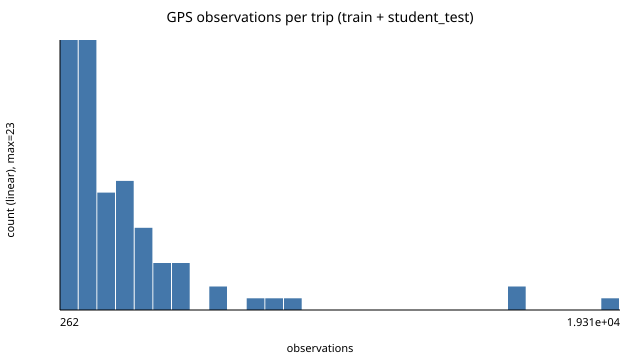

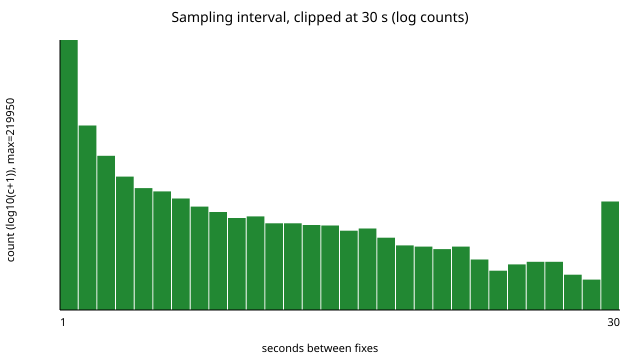

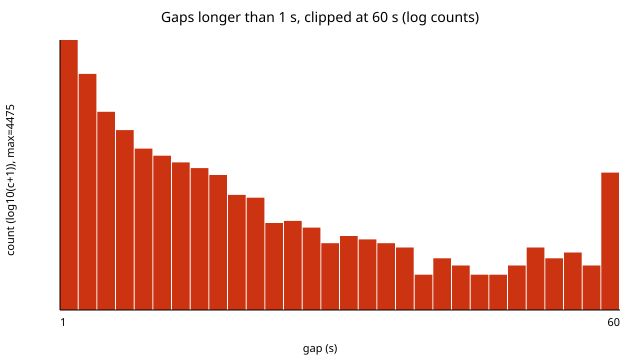

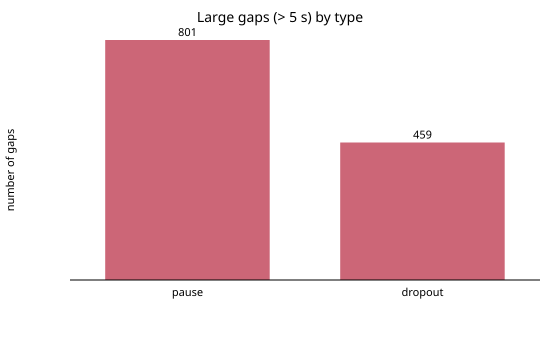

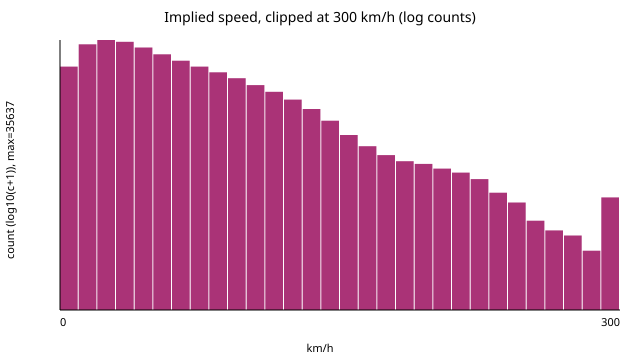

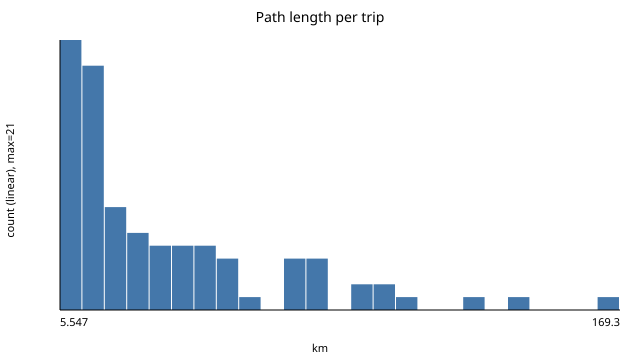

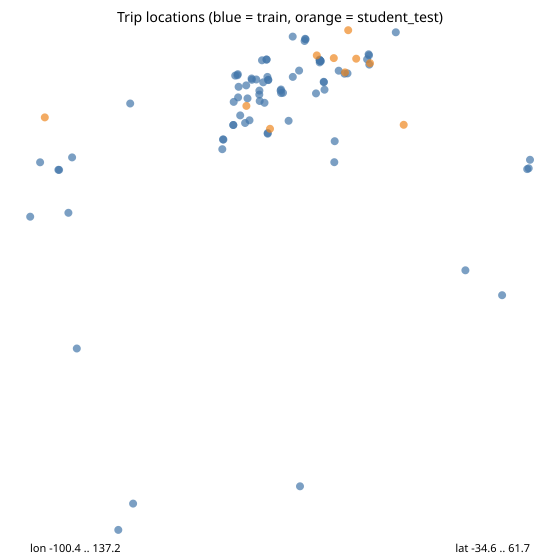

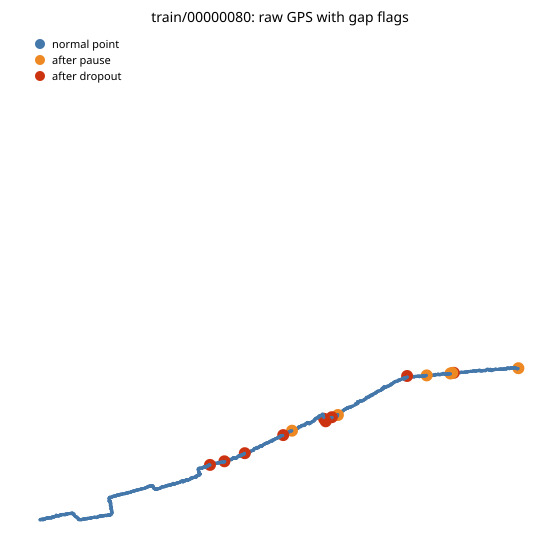

In [10]:
FIG = ROOT / "eda" / "figures"
for name in ["gps_obs_per_trip", "gps_sampling_interval", "gps_gap_sizes", "gps_gap_types",
             "gps_speed_distribution", "gps_path_length_km", "gps_trip_locations", "gps_sample_trajectory"]:
    display(SVG(filename=str(FIG / f"{name}.svg")))

## 9. Findings and decisions
- **Basic quality is clean:** no missing values, invalid coordinates, duplicate rows or backward timestamps in either partition; lon/lat order verified.
- **Sampling:** 96.7% of all steps are exactly 1 s apart (train 96.5%, student_test 98.6%), matching the roughly 97% in the dataset description.
- **Gaps:** 1,260 gaps longer than 5 s: 801 pauses and 459 dropouts. All dropouts are in train (none in student_test), so student_test is easier than train in this respect.
- **Speed spikes:** up to 648 km/h implied between consecutive fixes; these are GPS noise and are kept.
- **Trips span 25 UTM zones**, so each trip needs its own projection for distance calculations.
- **Decisions:** keep every point; flag pauses and dropouts; cap the time-difference feature at 60 s; add `segment_id`; no learned preprocessing is fitted here, so there is no train/test leakage from this stage.